<a href="https://colab.research.google.com/github/opangalazhar/Hello-Project---Naufal/blob/main/GAT%20(Heart%20Disease).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Drive & Library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# project  foldername

FOLDERNAME = "/content/"
!mkdir save_results

# load python files from foldername
import sys
sys.path.append(FOLDERNAME)

# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

Mounted at /content/drive


In [ ]:
!pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip

     - 17.8 MB 35.6 MB/s 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 3.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 686.1/686.1 kB 21.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 293.3/293.3 kB 19.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 24.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 60.6 MB/s eta 0:00:00
  Created wheel for ydata-profiling: filename=ydata_profiling-0.0.dev0-py2.py3-none-any.whl size=357914 sha256=82504cac17821d78df523787ebd8fb65478c320345c2c54144658a4c5c8c4658
  Stored in directory: /tmp/pip-ephem-wheel-cache-wjtg7v99/wheels/07/29/61/f533cc7cbd0a97efb2d1b94d3254a3e859a949367ba842577b
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=1b8aa1470e1587b51a088b21b804972276b1e620fd273a9b25e77db86d36c9f7
  Stored in director

In [ ]:
import os
import torch
os.environ['TORCH'] = torch.__version__
print(torch.__version__)

!pip install -q torch-scatter -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q torch-sparse -f https://data.pyg.org/whl/torch-${TORCH}.html
!pip install -q git+https://github.com/pyg-team/pytorch_geometric.git
!pip install torch-geometric

2.1.0+cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 73.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 36.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import warnings
import pandas as pd
import seaborn as sns
import torch
import networkx as nx
import matplotlib.pyplot as plt
import copy
from torch_geometric.transforms import NormalizeFeatures, GCNNorm
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from sklearn.metrics import roc_auc_score
from torch_geometric.utils import to_networkx, softmax, degree, to_undirected
from torch_geometric.data import Data, DataLoader

import scipy.sparse as sp

import torch.nn.functional as F
from torch.nn import Linear, Dropout, LayerNorm, ReLU
from torch_geometric.nn import GCNConv, GATConv
from torch import Tensor
import pickle
from torch_geometric.typing import Adj

warnings.filterwarnings('ignore')
from torch_geometric.typing import (OptPairTensor, Adj, Size, NoneType,
                                    OptTensor)

import torch_scatter
import torch.nn as nn
import torch.nn.functional as F
from pandas_profiling import ProfileReport
%matplotlib inline
pd.set_option('display.max_colwidth', None)

# EDA

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/heart_uci.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [ ]:
df['id'] = df.index + 1
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition,id
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0,1
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0,2
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0,3
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1,4
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,40,1,3,152,223,0,0,181,0,0.0,0,0,2,1,293
293,39,1,3,118,219,0,0,140,0,1.2,1,0,2,1,294
294,35,1,3,120,198,0,0,130,1,1.6,1,0,2,1,295
295,35,0,3,138,183,0,0,182,0,1.4,0,0,0,0,296


In [ ]:
df_cat = df.select_dtypes(np.number)
df_cat

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition,id
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0,1
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0,2
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0,3
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1,4
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,40,1,3,152,223,0,0,181,0,0.0,0,0,2,1,293
293,39,1,3,118,219,0,0,140,0,1.2,1,0,2,1,294
294,35,1,3,120,198,0,0,130,1,1.6,1,0,2,1,295
295,35,0,3,138,183,0,0,182,0,1.4,0,0,0,0,296


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
 14  id         297 non-null    int64  
dtypes: float64(1), int64(14)
memory usage: 34.9 KB


In [ ]:
df['oldpeak'] = df['oldpeak'].astype('int64')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        297 non-null    int64
 1   sex        297 non-null    int64
 2   cp         297 non-null    int64
 3   trestbps   297 non-null    int64
 4   chol       297 non-null    int64
 5   fbs        297 non-null    int64
 6   restecg    297 non-null    int64
 7   thalach    297 non-null    int64
 8   exang      297 non-null    int64
 9   oldpeak    297 non-null    int64
 10  slope      297 non-null    int64
 11  ca         297 non-null    int64
 12  thal       297 non-null    int64
 13  condition  297 non-null    int64
 14  id         297 non-null    int64
dtypes: int64(15)
memory usage: 34.9 KB


In [ ]:
np.isfinite(df).sum()

age          297
sex          297
cp           297
trestbps     297
chol         297
fbs          297
restecg      297
thalach      297
exang        297
oldpeak      297
slope        297
ca           297
thal         297
condition    297
id           297
dtype: int64

In [ ]:
np.isfinite(df).all()

age          True
sex          True
cp           True
trestbps     True
chol         True
fbs          True
restecg      True
thalach      True
exang        True
oldpeak      True
slope        True
ca           True
thal         True
condition    True
id           True
dtype: bool

In [ ]:
# Pandas profiling report
profile = ProfileReport(df, title='Heart Data', explorative=True)
# For notebook exploration
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
df_satu = df[df.condition == 1]
df_satu

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition,id
3,65,1,0,138,282,1,2,174,0,1,1,1,0,1,4
7,61,1,0,134,234,0,0,145,0,2,1,2,0,1,8
10,59,1,0,170,288,0,2,159,0,0,1,0,2,1,11
11,59,1,0,160,273,0,2,125,0,0,0,0,0,1,12
12,59,1,0,134,204,0,0,162,0,0,0,2,0,1,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
291,40,1,3,110,167,0,2,114,1,2,1,0,2,1,292
292,40,1,3,152,223,0,0,181,0,0,0,0,2,1,293
293,39,1,3,118,219,0,0,140,0,1,1,0,2,1,294
294,35,1,3,120,198,0,0,130,1,1,1,0,2,1,295


In [ ]:
profile = ProfileReport(df_satu, title='Heart Data', explorative=True)
# For notebook exploration
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
df_nol = df[df.condition == 0]
df_nol

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition,id
0,69,1,0,160,234,1,2,131,0,0,1,1,0,0,1
1,69,0,0,140,239,0,0,151,0,1,0,2,0,0,2
2,66,0,0,150,226,0,0,114,0,2,2,0,0,0,3
4,64,1,0,110,211,0,2,144,1,1,1,0,0,0,5
5,64,1,0,170,227,0,2,155,0,0,1,0,2,0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285,43,1,3,150,247,0,0,171,0,1,0,0,0,0,286
286,43,1,3,110,211,0,0,161,0,0,0,0,2,0,287
287,42,0,3,102,265,0,2,122,0,0,1,0,0,0,288
289,42,1,3,140,226,0,0,178,0,0,0,0,0,0,290


In [ ]:
profile = ProfileReport(df_nol, title='Heart Data', explorative=True)
# For notebook exploration
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# Construct Graph

In [ ]:
df_feature = df[['id','sex','restecg','cp','exang','oldpeak','slope','ca','thal','condition']]
df_edges = df[['age', 'thalach']]

In [ ]:
nodes = df_feature['id'].values # Setup id to node id mapping

map_id = {j:i for i, j in enumerate(nodes)} #mapping nodes to indexes

# create edge df that has transid mapped to nodeIDs
edges = df_edges.copy() # Copy Dataframe Edge
edges.age = edges.age.map(map_id) # get nodes age from edges list and filtered data
edges.thalach = edges.thalach.map(map_id) # get nodes thalach from edges list and filtered data
edges = edges.astype(int) # Change to integer


edge_index = np.array(edges.values).T #convert into an array
edge_index = torch.tensor(edge_index, dtype=torch.long).contiguous() # Create a tensor

print("shape of edge index is {}".format(edge_index.shape))

shape of edge index is torch.Size([2, 297])


In [ ]:
# Create weights tensor with same shape of edge_index
weights = torch.tensor([1] * edge_index.shape[1], dtype=torch.float32)

In [ ]:
# Mapping age to corresponding indices, to pass node features to the model
node_features = df_feature.copy() # Copy Dataframe feature

node_features.id = node_features.id.map(map_id) # Convert id to node id

node_s = node_features['condition'].index # index condition 0 & 1

labels = node_features['condition'].values # define label

node_features = node_features.drop(columns=['id','condition']) # drop id & condition = labels

node_t = torch.tensor(np.array(node_features.values, dtype=np.float32), dtype=torch.float32) # create tensor


# Make Dataset

In [ ]:
data = Data(x = node_t,
            edge_index = edge_index,
            edge_attr = weights,
            y = torch.tensor(labels, dtype=torch.float32), transform=NormalizeFeatures)


print(f'Number of nodes: {data.num_nodes}')
print(f'Number of features: {data.num_features}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Number of classes: {len(np.unique(data.y))}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self loops: {data.has_self_loops()}')
print(f'Is directed: {data.is_directed()}')

Number of nodes: 297
Number of features: 8
Number of edges: 297
Average node degree: 1.00
Number of classes: 2
Has isolated nodes: True
Has self loops: False
Is directed: True


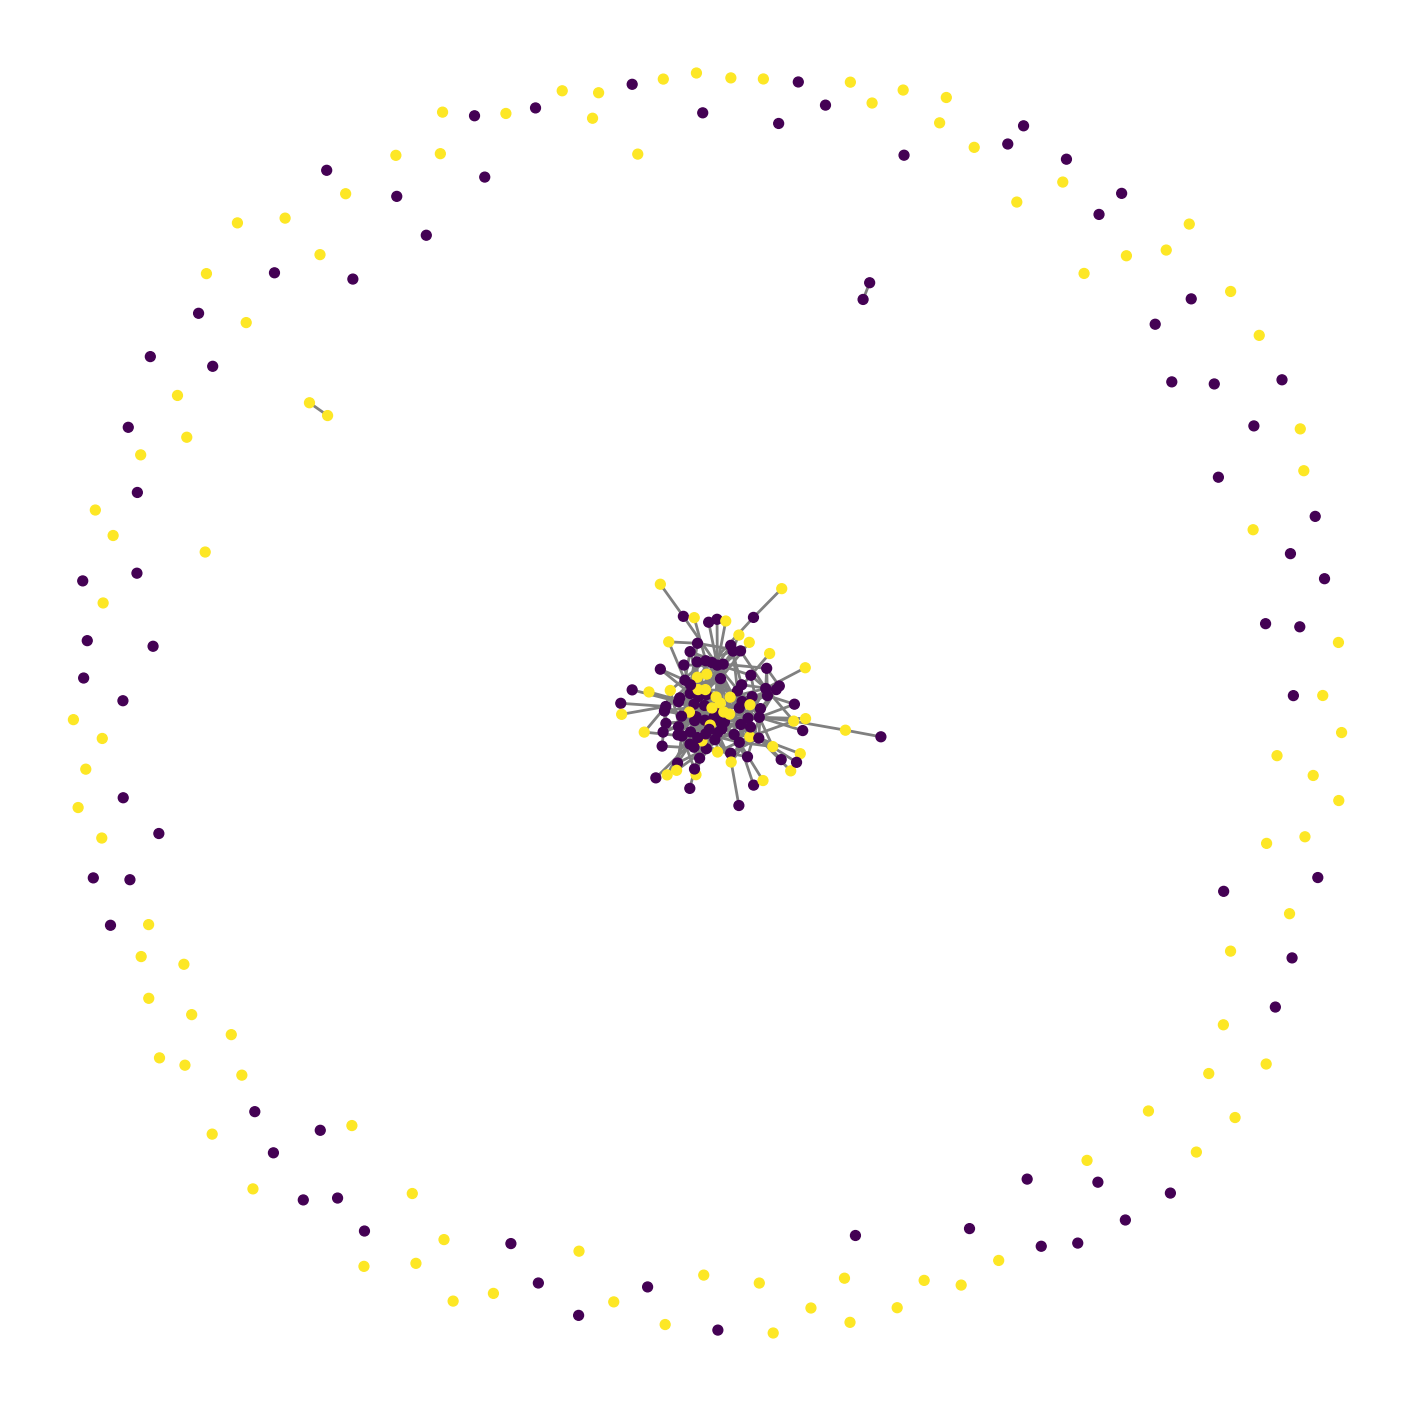

In [ ]:
G = to_networkx(data, to_undirected=True)
plt.figure(figsize=(18,18))
plt.axis('off')
nx.draw_networkx(G,
                 pos=nx.spring_layout(G, seed=0),
                 with_labels=False,
                 node_size=50,
                 node_color=data.y,
                 width=2,
                 edge_color="grey"
                 )
plt.show()

# Data Split

In [ ]:
train_id, testing_id = train_test_split(node_s.values, test_size=0.2, random_state=42)
train_id, valid_id = train_test_split(train_id, test_size=0.3, random_state=42)

data.train_id = torch.tensor(train_id, dtype=torch.long)
data.val_id = torch.tensor(valid_id, dtype=torch.long)
data.test_id = torch.tensor(testing_id, dtype=torch.long)


print("Train dataset size:", data.train_id.shape[0])
print("Validation dataset size:", data.val_id.shape[0])
print("Test dataset size:", data.test_id.shape[0])

Train dataset size: 165
Validation dataset size: 72
Test dataset size: 60


# Model

In [ ]:
class GAT(torch.nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim, args):
    super(GAT, self).__init__()
    self.conv1 = GATConv(input_dim, hidden_dim, heads=2)
    self.conv2 = GATConv(2 * hidden_dim, output_dim, heads=2, concat=False)

  def forward(self, data, adj=None):
    x, edge_index = data.x, data.edge_index
    x = F.dropout(x, p=0.3, training=self.training)
    x = F.elu(self.conv1(x, edge_index))
    x = F.dropout(x, p=0.3, training=self.training)
    x = self.conv2(x, edge_index)
    return F.sigmoid(x)

# Train, Test, and Validation

In [ ]:
class GnnTrain(object):
  def __init__(self, model):
    self.model = model
    self.metric_manager = MetricManager(modes=["train", "test", "valid"])

  def train(self, data, optimizer, criterion, scheduler, args):
    self.data = data
    print("Train & Validation")
    for epoch in range(args['epochs']):
      self.model.train()
      optimizer.zero_grad() #Clear gradients
      out = self.model(data)
      out = out.reshape((data.x.shape[0]))
      loss = criterion(out[data.train_id], data.y[data.train_id]) # Compute the loss solely based on the training nodes.

      # Train data
      target_labels = data.y.detach().cpu().numpy()[data.train_id]
      pred_scores = out.detach().cpu().numpy()[data.train_id]
      train_acc, train_f1, train_f1macro, train_aucroc, train_recall, train_precision, train_cm = self.metric_manager.store_metrics("train", pred_scores, target_labels)

      # Training Step
      loss.backward()
      optimizer.step()

      # Validation
      self.model.eval()
      target_labels = data.y.detach().cpu().numpy()[data.val_id]
      pred_scores = out.detach().cpu().numpy()[data.val_id]
      valid_acc, valid_f1, valid_f1macro, valid_aucroc, valid_recall, valid_precision, valid_cm = self.metric_manager.store_metrics("valid",
                                                                                            pred_scores,
                                                                                            target_labels)


      if epoch % 5 == 0:
        print(f'Epoch {epoch} | Loss: {loss:.3f} | Train Acc: {train_acc*100:>6.2f}% | F1-Score: {train_f1macro*100:>6.2f}% | Recall: {train_recall*100:>6.2f}% | Precision: {train_precision*100:>6.2f}%')
        print(f'Epoch {epoch} | Loss: {loss:.3f} | Validation Acc: {valid_acc*100:>6.2f}% | F1-Score: {valid_f1macro*100:>6.2f}% | Recall: {valid_recall*100:>6.2f}% | Precision: {valid_precision*100:>6.2f}%')

  def test(self, data, optimizer, criterion, scheduler, args):
    self.data = data
    self.model.eval()
    #torch.no_grad()
    out = self.model(data)
    out = out.reshape((data.x.shape[0]))

    # Test Data
    target_labels = data.y.detach().cpu().numpy()[data.test_id]
    pred_scores = out.detach().cpu().numpy()[data.test_id]
    test_acc, test_f1, test_f1macro, test_aucroc, test_recall, test_precision, test_cm = self.metric_manager.store_metrics("test", pred_scores, target_labels)
    print(f'test_acc: {test_acc:.4f} | test_f1: {test_f1macro:.4f} | test_recall: {test_recall:.4f} | test_precision: {test_precision:.4f}')

  def save_metrics(self, name, path="./save/"):
    file_to_store = open(path + name, "wb")
    pickle.dump(self.metric_manager, file_to_store)
    file_to_store.close()

  def save_model(self, name, path="./save/"):
    torch.save(self.model.state_dict(), path + name)

In [ ]:
class MetricManager(object):
  def __init__(self, modes=["train", "test", "valid"]):
    self.output = {}

    for mode in modes:
      self.output[mode] = {}
      self.output[mode]["accuracy"] = []
      self.output[mode]["f1micro"] = []
      self.output[mode]["f1macro"] = []
      self.output[mode]["aucroc"] = []
      self.output[mode]["recall"] = []
      self.output[mode]["precision"] = []
      self.output[mode]["cm"] = []

  def store_metrics(self, mode, pred_scores, target_labels, threshold=0.5):
    # calculate metrics
    pred_labels = pred_scores > threshold
    accuracy = accuracy_score(target_labels, pred_labels)
    f1micro = f1_score(target_labels, pred_labels, average='micro')
    f1macro = f1_score(target_labels, pred_labels, average='macro')
    aucroc = roc_auc_score(target_labels, pred_scores)
    recall = recall_score(target_labels, pred_labels)
    precision = precision_score(target_labels, pred_labels)
    cm = confusion_matrix(target_labels, pred_labels)

    # collect results
    self.output[mode]["accuracy"].append(accuracy)
    self.output[mode]["f1micro"].append(f1micro)
    self.output[mode]["f1macro"].append(f1macro)
    self.output[mode]["aucroc"].append(aucroc)
    self.output[mode]["recall"].append(recall)
    self.output[mode]["precision"].append(precision)
    self.output[mode]["cm"].append(cm)

    return accuracy, f1micro, f1macro, aucroc, recall, precision, cm

  def get_best_test(self, metric, mode="val"):

    # Get best results index
    best_results = {}
    i = np.array(self.output[mode][metric]).argmax()

    # Output
    for m in self.output[mode].keys():
      best_results[m] = self.output[mode][m][i]

    return best_results

  def get_best_valid(self, metric, mode="val"):

    # Get best results index
    best_results = {}
    i = np.array(self.output[mode][metric]).argmax()

    # Output
    for m in self.output[mode].keys():
      best_results[m] = self.output[mode][m][i]

    return best_results

# Performance

In [ ]:
args={"epochs":100,
      'lr':0.01,
      'weight_decay': 1e-4,
      'hidden_dim': 128,
      'dropout': 0.3,
      }

In [ ]:
model = GAT(data.num_node_features, args['hidden_dim'], 1, args)
model

GAT(
  (conv1): GATConv(8, 128, heads=2)
  (conv2): GATConv(256, 1, heads=2)
)

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=args['lr'], weight_decay=args['weight_decay'])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min')
#criterion = torch.nn.BCEWithLogitsLoss()
#criterion = torch.nn.CrossEntropyLoss()
criterion = torch.nn.BCELoss()

gat = GnnTrain(model)
gat.train(data, optimizer, criterion, scheduler, args)

gat.save_metrics("GAT.results", path=FOLDERNAME + "/save_results/")
gat.save_model("GAT.pth", path=FOLDERNAME + "/save_results/")

Train & Validation
Epoch 0 | Loss: 0.716 | Train Acc:  47.88% | F1-Score:  46.22% | Recall:  71.05% | Precision:  45.76%
Epoch 0 | Loss: 0.716 | Validation Acc:  44.44% | F1-Score:  43.35% | Recall:  63.64% | Precision:  42.86%
Epoch 5 | Loss: 0.586 | Train Acc:  68.48% | F1-Score:  68.06% | Recall:  61.84% | Precision:  67.14%
Epoch 5 | Loss: 0.586 | Validation Acc:  65.28% | F1-Score:  63.70% | Recall:  48.48% | Precision:  66.67%
Epoch 10 | Loss: 0.558 | Train Acc:  70.30% | F1-Score:  69.86% | Recall:  63.16% | Precision:  69.57%
Epoch 10 | Loss: 0.558 | Validation Acc:  68.06% | F1-Score:  66.17% | Recall:  48.48% | Precision:  72.73%
Epoch 15 | Loss: 0.551 | Train Acc:  72.73% | F1-Score:  71.52% | Recall:  56.58% | Precision:  78.18%
Epoch 15 | Loss: 0.551 | Validation Acc:  68.06% | F1-Score:  65.09% | Recall:  42.42% | Precision:  77.78%
Epoch 20 | Loss: 0.541 | Train Acc:  73.94% | F1-Score:  73.17% | Recall:  61.84% | Precision:  77.05%
Epoch 20 | Loss: 0.541 | Validation Ac

In [ ]:
gat.test(data, optimizer, criterion, scheduler, args)

test_acc: 0.7833 | test_f1: 0.7818 | test_recall: 0.7500 | test_precision: 0.7778
